<a href="https://colab.research.google.com/github/TreesaAbraham/svd-image-compression-MATH344L/blob/main/notebooks/01_image_as_matrix.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Treesa Abraham

In [2]:
print("hello from colab")

hello from colab


Part A: Grayscale photgraph is a matrix

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
A = data.camera()

Imports


In [4]:
print("Shape:", A.shape)
print("Data type:", A.dtype)
print("Smallest entry:", A.min())
print("Largest entry:", A.max())
print("Top-left 3 x 3 block:\n", A[:3, :3])

Shape: (512, 512)
Data type: uint8
Smallest entry: 0
Largest entry: 255
Top-left 3 x 3 block:
 [[200 200 200]
 [200 199 199]
 [199 199 199]]


Print the dimensions of the photo, the type of entries (8 bit entries), the minimum value for brightness to max (black to white and all the grey in between)
The top-left 3x3 block, is the top left three integers, and all of them are a light grey)

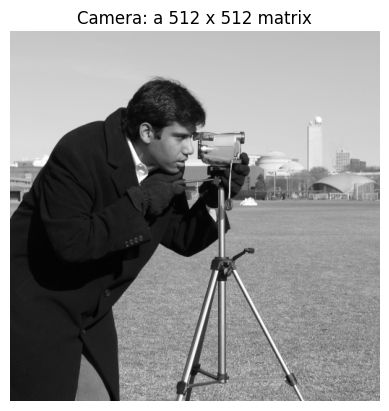

In [5]:
plt.imshow(A, cmap="gray", vmin=0, vmax=255)
plt.title("Camera: a 512 x 512 matrix")
plt.axis("off")
plt.show()

Show the photo in grayscale, and limit the black to white intensity to 0-255, give it the title ("Camera: a 512x512 mattrix), but don't show the axis, then show the image

Part B

In [6]:
C=data.coffee()
print("Color image shape: ", C.shape)
print("Data type:", C.dtype)
print("Smallest entry:", C.min())
print("Largest entry:", C.max())
#red values
print("Top-left 3 x 3 block, red:\n", C[:3, :3, 0])
#green values
print("Top-left 3 x 3 block, green:\n", C[:3, :3, 1])
#blue values
print("Top-left 3 x 3 block, blue:\n", C[:3, :3, 2])


Color image shape:  (400, 600, 3)
Data type: uint8
Smallest entry: 0
Largest entry: 255
Top-left 3 x 3 block, red:
 [[21 21 20]
 [21 21 20]
 [21 23 20]]
Top-left 3 x 3 block, green:
 [[13 13 11]
 [13 13 14]
 [14 13 14]]
Top-left 3 x 3 block, blue:
 [[ 8  9  8]
 [ 7  9  7]
 [ 7 10  9]]


Use the photo of the coffee, print the dimensions, the minimum to maximum for red, green, and blue. Since there are now 3 colors rather than just black and white, we have to have three matrices to represent the red, green, and blue, in the photo

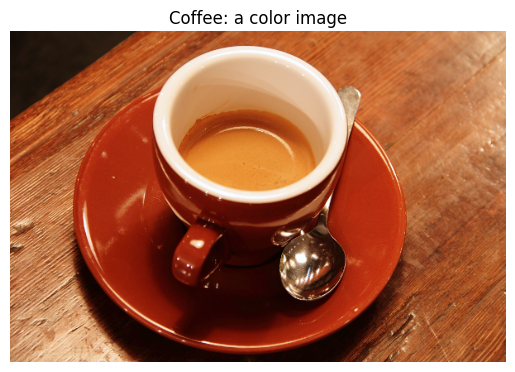

In [7]:
plt.imshow(C)
plt.title("Coffee: a color image")
plt.axis("off")
plt.show()

Show the photo in color, then show the image (no axis, and give it the title: Coffee: a Color image)

In [8]:
R = C[:, :, 0] # red channel
G = C[:, :, 1] # green channel
B = C[:, :, 2] # blue channel
print("Red channel shape:", R.shape)
print("Green channel shape:", G.shape)
print("Blue channel shape:", B.shape)

Red channel shape: (400, 600)
Green channel shape: (400, 600)
Blue channel shape: (400, 600)


splits the oclor image into separate color matrices, keeping all rows and matrices, but since the dimensions of the photo is 400x600 the shape remains the same regardless of the color matrices.

Part C:

In [9]:
x = np.array([200], dtype=np.uint8)
y = np.array([100], dtype=np.uint8)
print("uint8 200 + 100 =", x + y)
print("float 200 + 100 =", x.astype(float) + y.astype(float))

uint8 200 + 100 = [44]
float 200 + 100 = [300.]


since uint8 can't be more than 255, this is the remainder of 300-256. floats don't have a maximum of 256, so the second value shows the total value.


Note for coding:
Before doing linear algebra on image data, convert the image to floating-point numbers with
.astype(float). This avoids unwanted wraparound during calculations.

Part D

In [10]:
cross = np.array([
[0, 1, 1, 0],
[1, 1, 1, 1],
[1, 1, 1, 1],
[0, 1, 1, 0]
])
gradient = np.array([
[i + j for j in range(4)]
for i in range(4)
])
checker = np.array([
[(i + j + 1) % 2 for j in range(4)]
for i in range(4)
])
print(cross, gradient, checker)

[[0 1 1 0]
 [1 1 1 1]
 [1 1 1 1]
 [0 1 1 0]] [[0 1 2 3]
 [1 2 3 4]
 [2 3 4 5]
 [3 4 5 6]] [[1 0 1 0]
 [0 1 0 1]
 [1 0 1 0]
 [0 1 0 1]]


make 3 4x4 matrices as small black and white images 0 is black, 1 is white. The checker array uses %2 so that only 0 and 1 are part of the matrices, resulting in the checker matrix

In [11]:
print("Cross rank =", np.linalg.matrix_rank(cross))
print("Gradient rank =", np.linalg.matrix_rank(gradient))
print("Checkerboard rank =", np.linalg.matrix_rank(checker))

Cross rank = 2
Gradient rank = 2
Checkerboard rank = 2


rank=number of the pivots in each matrix (independent columns)

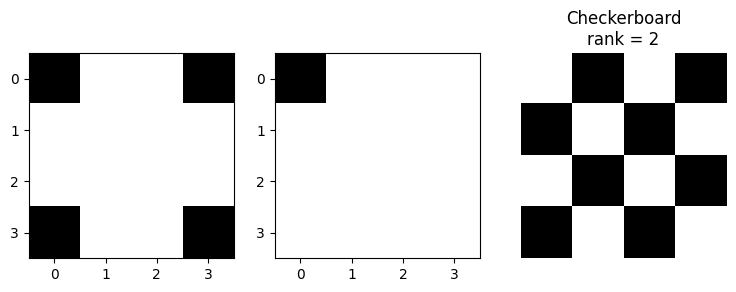

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
images = [("Cross", cross), ("Gradient", gradient),
("Checkerboard", checker)]
for ax, (name, M) in zip(axes, images):
  ax.imshow(M, cmap="gray", vmin=0, vmax=1)
ax.set_title(f"{name}\nrank = {np.linalg.matrix_rank(M)}")
ax.axis("off")
plt.show()

[[1 1 1 1]
 [0 0 0 0]
 [1 1 1 1]
 [0 0 0 0]]
Rank = 1


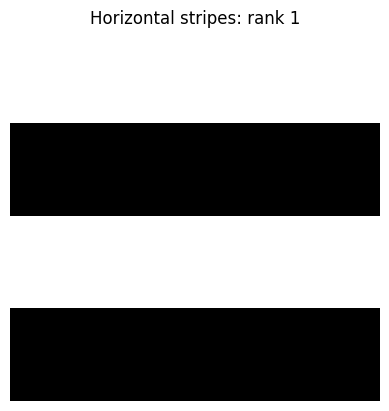

In [13]:
u = np.array([1, 0, 1, 0])
v = np.array([1, 1, 1, 1])
stripes = np.outer(u, v)
print(stripes)
print("Rank =", np.linalg.matrix_rank(stripes))
plt.imshow(stripes, cmap="gray", vmin=0, vmax=1)
plt.title("Horizontal stripes: rank 1")
plt.axis("off")
plt.show()

Using the same logic from the checkerboard, we can display the stripes. element of the matrices at i and j is u (ith) times j v (jth)
The rank is 1 since there is only one non-zero independent row in the matrix
Then to visualize it, any 1 means a white box, and every 0 means a black box